In [ ]:
import pandas as pd
import re

df = pd.read_csv("/content/drive/MyDrive/mini project/cleaned_hotel_maintenance_dataset.csv")

print("Dataset shape:", df.shape)
display(df[["complaint", "category"]].head())

Dataset shape: (1500, 8)


,complaint,category
0,Several corridor light covers on floor 9 are d...,Structural
1,Urgent: The treadmill in the gym caught fire b...,Appliance
2,Please note: Spa treatment room 18 massage tab...,Plumbing
3,Please note: The floor 11 corridor smoke detec...,General
4,The heating system in room 312 is not function...,Electrical


In [ ]:
def classify_hostel_category(text):
    text = text.lower()

    # -------------------------
    # 1. PLUMBING
    # -------------------------
    plumbing_keywords = [
        "water leak", "water leaking", "water leakage",
        "leaking water", "water dripping",
        "pipe leak", "pipe burst", "water pipe",
        "plumbing", "tap", "faucet",
        "sink", "wash basin", "washbasin",
        "toilet", "toilet flush", "flush",
        "shower", "bathtub", "bath tub",
        "drain", "drainage", "sewage",
        "sewage smell", "water pressure",
        "water supply", "hot water", "cold water",
        "water heater", "water pooling",
        "blocked toilet", "blocked drain",
        "overflowing toilet"
    ]

    # -------------------------
    # 2. ELECTRICAL
    # -------------------------
    electrical_keywords = [
        "electricity", "electrical", "electric shock",
        "electric vehicle", "charging point",
        "charging station", "power outage",
        "power failure", "no power",
        "without power", "power supply",
        "power socket", "power outlet",
        "wiring", "wire", "socket", "outlet",
        "switch", "circuit", "circuit breaker",
        "breaker", "fuse", "voltage",
        "electrical cupboard", "burning smell",
        "light bulb", "light not working",
        "lights not working", "lighting",
        "flickering light", "flickering lights",
        "fluorescent", "lamp",
        "fan", "ceiling fan", "exhaust fan",
        "motor fault", "motor",
        "air conditioning", "air conditioner",
        "heating system", "heating element",
        "thermostat", "oven", "electric oven",
        "treadmill", "machine caught fire"
    ]

    # -------------------------
    # 3. STRUCTURAL
    # -------------------------
    structural_keywords = [
        "wall", "walls", "ceiling",
        "roof", "floor", "flooring",
        "floor tile", "floor tiles",
        "tile", "tiles",
        "door frame", "window", "windows",
        "window frame",
        "crack", "cracked", "cracking",
        "broken wall", "structural",
        "building damage", "plaster",
        "paint peeling", "paint is peeling",
        "wallpaper peeling", "wallpaper",
        "ceiling damage", "roof damage",
        "hinge", "door hinge",
        "damaged flooring"
    ]

    # -------------------------
    # 4. GENERAL
    # -------------------------
    general_keywords = [
        "housekeeping", "cleaning", "deep cleaning",
        "dirty", "dust", "dusty",
        "stain", "stained", "carpet",
        "furniture", "bed", "chair",
        "table", "desk", "mattress",
        "wardrobe",
        "wifi", "wi-fi", "internet",
        "network", "tv", "television",
        "remote", "hdmi",
        "phone", "telephone",
        "cctv", "security", "camera",
        "lock", "key", "alarm",
        "smoke detector",
        "elevator", "lift",
        "pest", "insect", "cockroach",
        "mosquito", "rodent", "rat",
        "garden", "gardening",
        "landscaping", "grass", "hedge",
        "pool", "swimming pool",
        "pool chemical",
        "gym equipment",
        "conference", "whiteboard",
        "parking", "parking bay",
        "parking marking",
        "fire extinguisher",
        "broken furniture"
    ]

    # -------------------------
    # Priority order
    # -------------------------

    if any(keyword in text for keyword in plumbing_keywords):
        return "Plumbing"

    if any(keyword in text for keyword in electrical_keywords):
        return "Electrical"

    if any(keyword in text for keyword in structural_keywords):
        return "Structural"

    return "General"



df["hostel_category"] = df["complaint"].apply(
    classify_hostel_category
)

display(
    df[[
        "complaint",
        "category",
        "hostel_category"
    ]].head(20)
)

,complaint,category,hostel_category
0,Several corridor light covers on floor 9 are d...,Structural,Structural
1,Urgent: The treadmill in the gym caught fire b...,Appliance,Electrical
2,Please note: Spa treatment room 18 massage tab...,Plumbing,General
3,Please note: The floor 11 corridor smoke detec...,General,Structural
4,The heating system in room 312 is not function...,Electrical,Electrical
5,Urgent: The flip chart stand in conference roo...,Furniture,General
6,Guest complaint: The fire exit sign in the lob...,Structural,General
7,Staff report: There is no electricity in room ...,HVAC,Electrical
8,Staff report: Parking level 4 has a strong smo...,Safety/Security,General
9,Please note: Room 172 phone is dead and guest ...,Furniture,General


In [ ]:
print("Hostel Category Distribution:")
print(df["hostel_category"].value_counts())
category_percentage = (
    df["hostel_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(category_percentage)

Hostel Category Distribution:
hostel_category
General       712
Structural    354
Plumbing      237
Electrical    197
Name: count, dtype: int64
hostel_category
General       47.47
Structural    23.60
Plumbing      15.80
Electrical    13.13
Name: proportion, dtype: float64


In [ ]:
for category in ["Electrical", "Plumbing", "Structural", "General"]:

    print("\n" + "=" * 70)
    print(category)
    print("=" * 70)

    samples = df[
        df["hostel_category"] == category
    ]["complaint"].sample(
        min(10, len(df[df["hostel_category"] == category])),
        random_state=42
    )

    for complaint in samples:
        print("-", complaint)


Electrical
- Staff report: The aromatherapy diffuser in the spa waiting area is broken. Please advise on timeline.
- The air conditioning in room 667 has completely stopped working. Guest is very upset and demanding immediate attention. Front desk has been notified.
- Guest complaint: The treadmill in the gym caught fire briefly due to a motor fault. Gym evacuated. Urgent inspection needed. Guest is waiting for resolution.
- Urgent: The bathroom light in room 595 flickers when turned on. Needs electrical check. Front desk has been notified.
- Staff report: The gym has no air conditioning in extreme heat. Unsafe for guests exercising. Please advise on timeline.
- The bathroom exhaust fan in room 787 is very noisy and disturbing the guest at night. Guest is waiting for resolution.
- Room 405 has a flickering light in the bathroom. Bulb or fixture needs to be checked.
- Staff report: The rooftop signage lighting has two letters not illuminating. Front desk has been notified.
- Please not

In [ ]:
category_mapping = pd.crosstab(
    df["category"],
    df["hostel_category"]
)

display(category_mapping)

hostel_category,Electrical,General,Plumbing,Structural
category,,,,
Appliance,33,75,24,23
Electrical,31,75,32,48
Elevator,3,14,0,35
Furniture,18,75,9,23
General,5,65,20,55
HVAC,25,64,9,12
Housekeeping,1,45,4,36
Internet/AV,16,67,10,4
Landscaping,1,19,1,19


In [ ]:
output_file = "hostel_maintenance_reclassified.csv"

df.to_csv(
    output_file,
    index=False
)

print("Saved:", output_file)
from google.colab import files

files.download(output_file)

Saved: hostel_maintenance_reclassified.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print(df["hostel_category"].value_counts())

hostel_category
General       712
Structural    354
Plumbing      237
Electrical    197
Name: count, dtype: int64


optimizing

In [ ]:
general_samples = df[
    df["hostel_category"] == "General"
]["complaint"].sample(40, random_state=42)

for i, complaint in enumerate(general_samples, 1):
    print(f"{i}. {complaint}")

1. Please note: Elevator 17 suddenly dropped before stopping. Guest reported feeling unsafe. This has been reported before.
2. Staff report: The electric vehicle charging point in bay 16 is showing a fault error. Guest is waiting for resolution.
3. Parking bay marking lines on level 6 are faded and barely visible. Reported by housekeeping staff.
4. Garden hedges near the main entrance are overgrown and need trimming.
5. Staff report: WiFi signal is very weak in room 475. Guest is unable to connect for work. Please advise on timeline.
6. The minibar in room 568 stopped cooling. Items inside are warm.
7. Guest complaint: The ice machine at the bar is producing very little ice. Cannot keep up with demand. Reported by housekeeping staff.
8. Staff report: The sauna heating element has malfunctioned and is producing smoke. Please advise on timeline.
9. A vehicle has leaked a large amount of oil in parking bay 3. Slip hazard. Guest has requested an update.
10. Please note: The minibar in room

In [ ]:
for category in ["Electrical", "Plumbing", "Structural", "General"]:

    print("\n" + "=" * 70)
    print(category)
    print("=" * 70)

    samples = df[
        df["hostel_category"] == category
    ]["complaint"].sample(
        min(20, len(df[df["hostel_category"] == category])),
        random_state=42
    )

    for i, complaint in enumerate(samples, 1):
        print(f"{i}. {complaint}")


Electrical
1. Staff report: The aromatherapy diffuser in the spa waiting area is broken. Please advise on timeline.
2. The air conditioning in room 667 has completely stopped working. Guest is very upset and demanding immediate attention. Front desk has been notified.
3. Guest complaint: The treadmill in the gym caught fire briefly due to a motor fault. Gym evacuated. Urgent inspection needed. Guest is waiting for resolution.
4. Urgent: The bathroom light in room 595 flickers when turned on. Needs electrical check. Front desk has been notified.
5. Staff report: The gym has no air conditioning in extreme heat. Unsafe for guests exercising. Please advise on timeline.
6. The bathroom exhaust fan in room 787 is very noisy and disturbing the guest at night. Guest is waiting for resolution.
7. Room 405 has a flickering light in the bathroom. Bulb or fixture needs to be checked.
8. Staff report: The rooftop signage lighting has two letters not illuminating. Front desk has been notified.
9. P

In [ ]:
print(df.columns.tolist())

['id', 'complaint', 'area', 'category', 'priority', 'department', 'estimated_resolution_hours', 'priority_original', 'hostel_category']


NLP


In [ ]:
import re
import nltk

from nltk.corpus import stopwords

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    # Join words
    text = " ".join(words)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["cleaned_complaint"] = df["complaint"].apply(preprocess_text)

print(df[["complaint", "cleaned_complaint"]].head(10))

                                           complaint  \
0  Several corridor light covers on floor 9 are d...   
1  Urgent: The treadmill in the gym caught fire b...   
2  Please note: Spa treatment room 18 massage tab...   
3  Please note: The floor 11 corridor smoke detec...   
4  The heating system in room 312 is not function...   
5  Urgent: The flip chart stand in conference roo...   
6  Guest complaint: The fire exit sign in the lob...   
7  Staff report: There is no electricity in room ...   
8  Staff report: Parking level 4 has a strong smo...   
9  Please note: Room 172 phone is dead and guest ...   

                                   cleaned_complaint  
0  several corridor light covers floor dusty yell...  
1  urgent treadmill gym caught fire briefly due m...  
2  please note spa treatment room massage table b...  
3  please note floor corridor smoke detector keep...  
4  heating system room functioning guest freezing...  
5  urgent flip chart stand conference room bent l... 

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
print("Empty cleaned complaints:",
      (df["cleaned_complaint"].str.len() == 0).sum())

Empty cleaned complaints: 0


tf idf

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_tfidf = tfidf_vectorizer.fit_transform(
    df["cleaned_complaint"]
)

print("TF-IDF matrix shape:", X_tfidf.shape)

TF-IDF matrix shape: (1500, 3023)


train test split


In [ ]:
from sklearn.model_selection import train_test_split

# Target variables
y_category = df["hostel_category"]
y_priority = df["priority"]

# Train/Test Split
X_train_tfidf, X_test_tfidf, \
y_category_train, y_category_test, \
y_priority_train, y_priority_test = train_test_split(
    X_tfidf,
    y_category,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])

print("\nCategory distribution - Training:")
print(y_category_train.value_counts())

print("\nCategory distribution - Testing:")
print(y_category_test.value_counts())

print("\nPriority distribution - Training:")
print(y_priority_train.value_counts())

Training samples: 1200
Testing samples: 300

Category distribution - Training:
hostel_category
General       570
Structural    283
Plumbing      190
Electrical    157
Name: count, dtype: int64

Category distribution - Testing:
hostel_category
General       142
Structural     71
Plumbing       47
Electrical     40
Name: count, dtype: int64

Priority distribution - Training:
priority
Medium    561
High      351
Low       288
Name: count, dtype: int64


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_train_smote, y_category_train_smote = smote.fit_resample(
    X_train_tfidf,
    y_category_train
)

print("Category distribution BEFORE SMOTE:")
print(y_category_train.value_counts())

print("\nCategory distribution AFTER SMOTE:")
print(y_category_train_smote.value_counts())

print("\nShape before SMOTE:", X_train_tfidf.shape)
print("Shape after SMOTE:", X_train_smote.shape)

Category distribution BEFORE SMOTE:
hostel_category
General       570
Structural    283
Plumbing      190
Electrical    157
Name: count, dtype: int64

Category distribution AFTER SMOTE:
hostel_category
General       570
Structural    570
Plumbing      570
Electrical    570
Name: count, dtype: int64

Shape before SMOTE: (1200, 3023)
Shape after SMOTE: (2280, 3023)


In [ ]:
from sklearn.linear_model import LogisticRegression

category_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model.fit(
    X_train_smote,
    y_category_train_smote
)

print("Category model training completed.")

Category model training completed.


In [ ]:
y_category_pred = category_model.predict(X_test_tfidf)

print("Category predictions completed.")

Category predictions completed.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Accuracy
category_accuracy = accuracy_score(
    y_category_test,
    y_category_pred
)

print("Category Model Accuracy:")
print(f"{category_accuracy * 100:.2f}%")

# Classification report
print("\nCategory Classification Report:")
print(
    classification_report(
        y_category_test,
        y_category_pred
    )
)

Category Model Accuracy:
100.00%

Category Classification Report:
              precision    recall  f1-score   support

  Electrical       1.00      1.00      1.00        40
     General       1.00      1.00      1.00       142
    Plumbing       1.00      1.00      1.00        47
  Structural       1.00      1.00      1.00        71

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



In [ ]:
import numpy as np

feature_names = tfidf_vectorizer.get_feature_names_out()

for i, class_name in enumerate(category_model.classes_):
    top_indices = np.argsort(
        category_model.coef_[i]
    )[-15:][::-1]

    print("\n" + "=" * 50)
    print(class_name)
    print("=" * 50)

    for index in top_indices:
        print(feature_names[index])


Electrical
lighting
air conditioning
conditioning
electrical
air
gym
night
fan
cold
burning smell
burning
exhaust
oven
temperature
heating

General
entrance
cannot
lobby
need
system
parking
machine
main
working
properly
use
phone
music
one
garden

Plumbing
water
shower
drain
toilet
room
sink
hot
hot water
water leak
bathroom
leaking
wash
pipe
blocked
drain cover

Structural
floor
rooftop
wall
elevator
paint
tiles
near
crack
walls
peeling
window
minor
lights
mirror
hinge


without smote

In [ ]:
category_model_no_smote = LogisticRegression(
    max_iter=1000,
    random_state=42
)

category_model_no_smote.fit(
    X_train_tfidf,
    y_category_train
)

y_category_pred_no_smote = category_model_no_smote.predict(
    X_test_tfidf
)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

accuracy_no_smote = accuracy_score(
    y_category_test,
    y_category_pred_no_smote
)

print(f"Category Accuracy WITHOUT SMOTE: {accuracy_no_smote * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_category_test,
        y_category_pred_no_smote
    )
)

Category Accuracy WITHOUT SMOTE: 97.00%

Classification Report:
              precision    recall  f1-score   support

  Electrical       1.00      0.85      0.92        40
     General       0.94      1.00      0.97       142
    Plumbing       1.00      0.94      0.97        47
  Structural       1.00      1.00      1.00        71

    accuracy                           0.97       300
   macro avg       0.99      0.95      0.96       300
weighted avg       0.97      0.97      0.97       300



#priority model

In [ ]:
priority_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

priority_model.fit(
    X_train_tfidf,
    y_priority_train
)

y_priority_pred = priority_model.predict(
    X_test_tfidf
)

print("Priority model training completed.")

Priority model training completed.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate accuracy
priority_accuracy = accuracy_score(
    y_priority_test,
    y_priority_pred
)

print("Priority Model Accuracy:")
print(f"{priority_accuracy * 100:.2f}%")

# Classification report
print("\nPriority Classification Report:")
print(
    classification_report(
        y_priority_test,
        y_priority_pred
    )
)

Priority Model Accuracy:
98.33%

Priority Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        99
         Low       0.99      0.95      0.97        83
      Medium       0.97      0.99      0.98       118

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



#Evaluation

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Model": ["Category Model", "Priority Model"],
    "Accuracy": [
        accuracy_score(y_category_test, y_category_pred_no_smote),
        accuracy_score(y_priority_test, y_priority_pred)
    ],
    "Precision": [
        precision_score(
            y_category_test,
            y_category_pred_no_smote,
            average="weighted"
        ),
        precision_score(
            y_priority_test,
            y_priority_pred,
            average="weighted"
        )
    ],
    "Recall": [
        recall_score(
            y_category_test,
            y_category_pred_no_smote,
            average="weighted"
        ),
        recall_score(
            y_priority_test,
            y_priority_pred,
            average="weighted"
        )
    ],
    "F1-Score": [
        f1_score(
            y_category_test,
            y_category_pred_no_smote,
            average="weighted"
        ),
        f1_score(
            y_priority_test,
            y_priority_pred,
            average="weighted"
        )
    ]
})

# Convert scores to percentages
results[["Accuracy", "Precision", "Recall", "F1-Score"]] *= 100

print(results.round(2))

            Model  Accuracy  Precision  Recall  F1-Score
0  Category Model     97.00      97.18   97.00     96.95
1  Priority Model     98.33      98.35   98.33     98.33


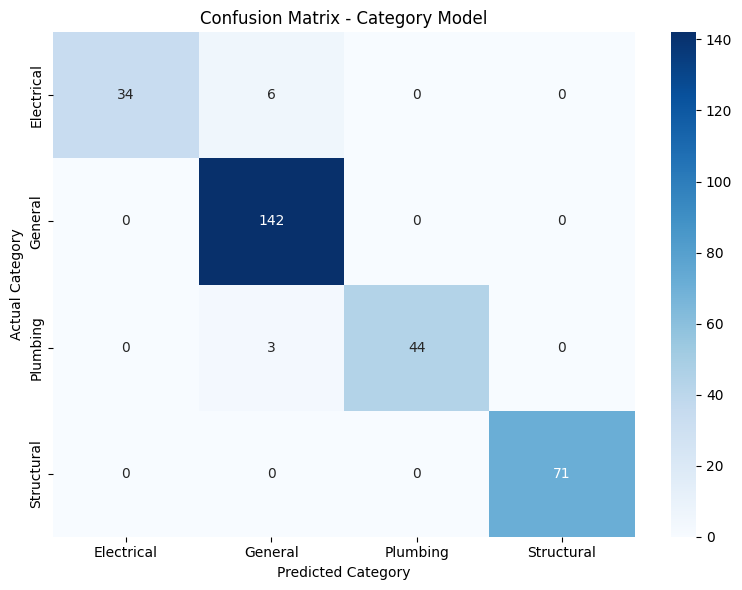

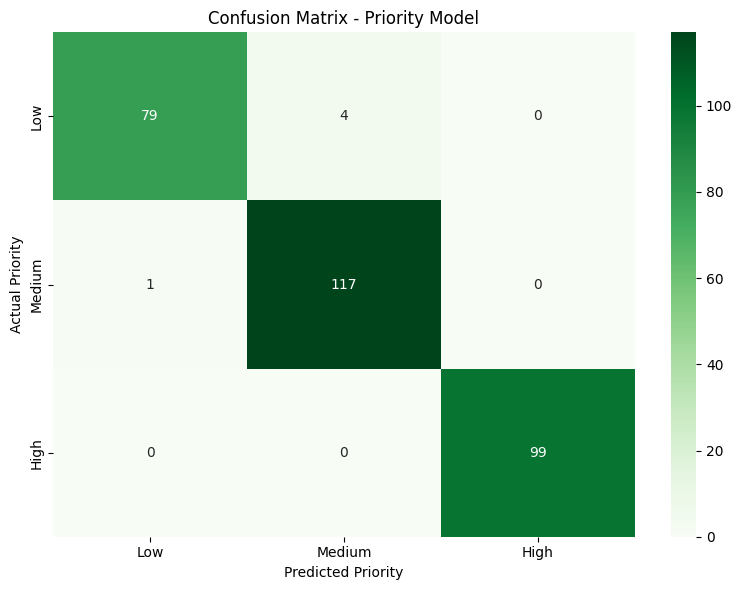

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =========================================================
# 1. CATEGORY MODEL - CONFUSION MATRIX
# =========================================================

category_labels = ["Electrical", "General", "Plumbing", "Structural"]

cm_category = confusion_matrix(
    y_category_test,
    y_category_pred_no_smote,
    labels=category_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_category,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=category_labels,
    yticklabels=category_labels
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Confusion Matrix - Category Model")

plt.tight_layout()
plt.show()


# =========================================================
# 2. PRIORITY MODEL - CONFUSION MATRIX
# =========================================================

priority_labels = ["Low", "Medium", "High"]

cm_priority = confusion_matrix(
    y_priority_test,
    y_priority_pred,
    labels=priority_labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_priority,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=priority_labels,
    yticklabels=priority_labels
)

plt.xlabel("Predicted Priority")
plt.ylabel("Actual Priority")
plt.title("Confusion Matrix - Priority Model")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Calculate weighted metrics
category_metrics = [
    accuracy_score(y_category_test, y_category_pred_no_smote) * 100,
    precision_score(
        y_category_test,
        y_category_pred_no_smote,
        average="weighted"
    ) * 100,
    recall_score(
        y_category_test,
        y_category_pred_no_smote,
        average="weighted"
    ) * 100,
    f1_score(
        y_category_test,
        y_category_pred_no_smote,
        average="weighted"
    ) * 100
]

priority_metrics = [
    accuracy_score(y_priority_test, y_priority_pred) * 100,
    precision_score(
        y_priority_test,
        y_priority_pred,
        average="weighted"
    ) * 100,
    recall_score(
        y_priority_test,
        y_priority_pred,
        average="weighted"
    ) * 100,
    f1_score(
        y_priority_test,
        y_priority_pred,
        average="weighted"
    ) * 100
]

metrics_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score"],
    "Category Model": category_metrics,
    "Priority Model": priority_metrics
})

print(metrics_df.round(2))

      Metric  Category Model  Priority Model
0   Accuracy           97.00           98.33
1  Precision           97.18           98.35
2     Recall           97.00           98.33
3   F1-Score           96.95           98.33


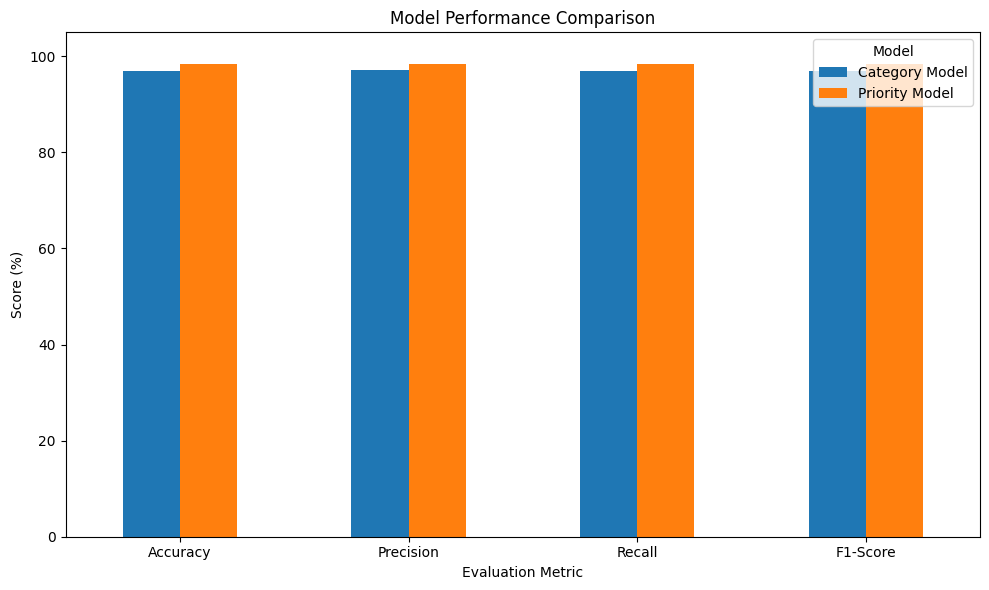

In [ ]:
metrics_df.plot(
    x="Metric",
    y=["Category Model", "Priority Model"],
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("Model Performance Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Model")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# EXTERNAL DATA TESTING
# ============================================================

# External complaints that were NOT used during model training
external_complaints = [
    "The bathroom tap in my room is leaking continuously.",
    "There is no electricity in my room and the power socket is not working.",
    "The wall in the corridor has a large crack.",
    "The WiFi connection in my room is very weak.",
    "Water is leaking from the ceiling and falling onto the floor.",
    "The ceiling fan is not working properly.",
    "The door hinge is broken and the door is difficult to close.",
    "The room furniture is damaged and needs replacement."
]

# ------------------------------------------------------------
# 1. Preprocess external complaints
# ------------------------------------------------------------

external_cleaned = [
    preprocess_text(complaint)
    for complaint in external_complaints
]

# ------------------------------------------------------------
# 2. Convert using the EXISTING TF-IDF vectorizer
# ------------------------------------------------------------

X_external_tfidf = tfidf_vectorizer.transform(
    external_cleaned
)

print("External data transformed successfully.")
print("TF-IDF shape:", X_external_tfidf.shape)

# ------------------------------------------------------------
# 3. Predict CATEGORY
# ------------------------------------------------------------

external_category_predictions = category_model_no_smote.predict(
    X_external_tfidf
)

# ------------------------------------------------------------
# 4. Predict PRIORITY
# ------------------------------------------------------------

external_priority_predictions = priority_model.predict(
    X_external_tfidf
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

external_results = pd.DataFrame({
    "Complaint": external_complaints,
    "Predicted Category": external_category_predictions,
    "Predicted Priority": external_priority_predictions
})

display(external_results)

External data transformed successfully.
TF-IDF shape: (8, 3023)


,Complaint,Predicted Category,Predicted Priority
0,The bathroom tap in my room is leaking continu...,Plumbing,Medium
1,There is no electricity in my room and the pow...,General,High
2,The wall in the corridor has a large crack.,Structural,Low
3,The WiFi connection in my room is very weak.,General,Medium
4,Water is leaking from the ceiling and falling ...,Plumbing,High
5,The ceiling fan is not working properly.,General,Medium
6,The door hinge is broken and the door is diffi...,General,Medium
7,The room furniture is damaged and needs replac...,General,Medium


In [ ]:
# ============================================================
# EXTERNAL DATA - ACTUAL / GROUND TRUTH LABELS
# ============================================================

# Correct labels for each external complaint
actual_categories = [
    "Plumbing",
    "Electrical",
    "Structural",
    "General",
    "Plumbing",
    "Electrical",
    "Structural",
    "General"
]

actual_priorities = [
    "Medium",
    "High",
    "Low",
    "Medium",
    "High",
    "Medium",
    "Medium",
    "Medium"
]

# Add actual labels to the results table
external_results["Actual Category"] = actual_categories
external_results["Actual Priority"] = actual_priorities

display(external_results)

,Complaint,Predicted Category,Predicted Priority,Actual Category,Actual Priority
0,The bathroom tap in my room is leaking continu...,Plumbing,Medium,Plumbing,Medium
1,There is no electricity in my room and the pow...,General,High,Electrical,High
2,The wall in the corridor has a large crack.,Structural,Low,Structural,Low
3,The WiFi connection in my room is very weak.,General,Medium,General,Medium
4,Water is leaking from the ceiling and falling ...,Plumbing,High,Plumbing,High
5,The ceiling fan is not working properly.,General,Medium,Electrical,Medium
6,The door hinge is broken and the door is diffi...,General,Medium,Structural,Medium
7,The room furniture is damaged and needs replac...,General,Medium,General,Medium
